# 03: Validation protocol and linear baseline

Study level 2 (regression and validation). Notebook 02 gave the age-only clock and its score on the FD001 test set. From here on the test set stays untouched until the end of the project, so this notebook builds the protocol that every later model is compared with, and the first sensor-based model under it.

Questions, each answered by one section and collected in the Decisions cell at the end:

1. How are models compared during development? Folds, cut points, metrics.
2. What does the clock score under that protocol? This is the development baseline.
3. How far does a linear model on the sensors get, and where does it fail?
4. How much does a row-wise split inflate the score, and for which models?
5. Does the linear model beat the clock?

The theory behind each section is in `docs/learning/02-regression-validation.md`.

## 1. The development protocol

Three decisions, made once and reused by every later notebook. The code lives in `src/turbofan_rul/validation.py` so that notebooks 04 onward import the same folds and cut points instead of rebuilding them.

- **Folds by engine.** Every engine is entirely in training or entirely in validation (DIMAP 2.7). Five folds of 20 engines.
- **Cut points like the test set.** Each validation engine is evaluated at truncated histories, against its true, uncapped remaining life (DIMAP 2.8).
- **Metrics on the test scale.** RMSE, and the PHM08 score rescaled to 100 predictions, so numbers from this protocol sit on the same scale as the 100-engine test set.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from turbofan_rul.config import MIN_HISTORY, N_CUTS_PER_ENGINE, N_FOLDS, PLANNING_LIMIT
from turbofan_rul.data_loading import add_rul_labels, load_subset
from turbofan_rul.validation import engine_folds, sample_cut_points

df = add_rul_labels(load_subset("FD001", split="train"))  # `rul` is capped at 125
lifetimes = df.groupby("unit")["cycle"].max().rename("lifetime")
df.shape

(20631, 27)

### 1a. Folds stratified by lifetime

Notebook 01 left a warning: lifetimes have a long right tail (128 to 362 cycles), and with only 100 engines a random split can leave a fold without long-lived engines. That fold would never measure the hardest cases, the ones where the clock failed worst in notebook 02.

`engine_folds` sorts engines by lifetime, takes them in blocks of five, and deals the five fold labels in random order inside each block. Each fold gets one engine from every lifetime block.

In [2]:
folds = engine_folds(df)
df["fold"] = df["unit"].map(folds)

assert folds.index.is_unique and len(folds) == 100, "every engine in exactly one fold"
assert df.groupby("unit")["fold"].nunique().eq(1).all(), "no engine split across folds"

fold_summary = lifetimes.groupby(folds).describe()[["count", "min", "50%", "max"]]
fold_summary.columns = ["engines", "shortest", "median life", "longest"]
fold_summary.astype(int)

,engines,shortest,median life,longest
fold,,,,
0,20,137,199,341
1,20,147,198,362
2,20,128,198,336
3,20,137,198,313
4,20,135,197,293


### 1b. Cut points

A cut at cycle $c$ means the model sees cycles 1 to $c$ of an engine and predicts how many remain. The rule for where cuts can fall comes from the scenario, not from the test file:

- **At least 30 cycles observed** (`MIN_HISTORY`). Level 3 will use windows of up to 30 cycles, and a cut earlier than that would leave them half empty.
- **True remaining life between 1 and 150** (`PLANNING_LIMIT`). The planner only needs predictions for engines that could reach the shop soon. An engine with 300 cycles left is not a planning decision, and scoring it would reward predicting the cap well.
- **10 cuts per engine** (`N_CUTS_PER_ENGINE`), drawn without replacement. One cut per engine made the linear model's RMSE swing between 44 and 57 depending on the draw (DIMAP 2.8). Ten cuts per engine make the score far less dependent on luck.

In [3]:
cuts = sample_cut_points(df)
cuts["fold"] = cuts["unit"].map(folds)

assert (cuts["cycle"] >= MIN_HISTORY).all()
assert cuts["rul_true"].between(1, PLANNING_LIMIT).all()
assert cuts.groupby("unit").size().eq(N_CUTS_PER_ENGINE).all(), "every engine has enough eligible cycles"

print(f"{len(cuts)} cut points, {cuts['unit'].nunique()} engines, {N_CUTS_PER_ENGINE} per engine")
cuts.groupby("fold").agg(cuts=("unit", "size"), engines=("unit", "nunique"),
                         median_rul=("rul_true", "median")).astype(int)

1000 cut points, 100 engines, 10 per engine


,cuts,engines,median_rul
fold,,,
0,200,20,72
1,200,20,73
2,200,20,74
3,200,20,66
4,200,20,64


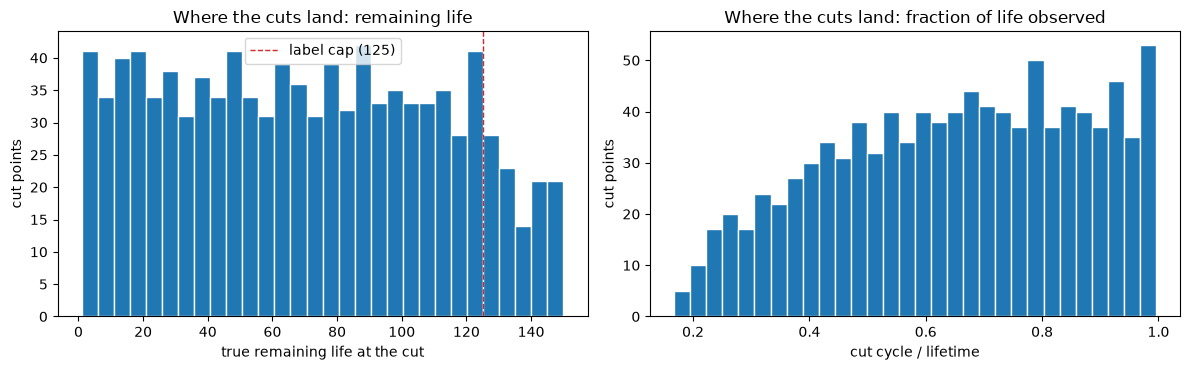

Share of cuts with true RUL above the cap of 125: 11%


In [4]:
cuts["life_fraction"] = cuts["cycle"] / cuts["unit"].map(lifetimes)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(cuts["rul_true"], bins=30, edgecolor="white")
axes[0].axvline(125, color="C3", ls="--", lw=1, label="label cap (125)")
axes[0].set(xlabel="true remaining life at the cut", ylabel="cut points", title="Where the cuts land: remaining life")
axes[0].legend()
axes[1].hist(cuts["life_fraction"], bins=30, edgecolor="white")
axes[1].set(xlabel="cut cycle / lifetime", ylabel="cut points", title="Where the cuts land: fraction of life observed")
plt.tight_layout()
plt.show()

print(f"Share of cuts with true RUL above the cap of 125: {(cuts['rul_true'] > 125).mean():.0%}")

**Reading.** Every fold has 20 engines, a median life of 197 to 199 cycles, and at least one engine above 290 cycles. The stratification did its job: the long-lived tail is in every validation fold.

The 1,000 cut points spread almost evenly over true remaining life from 1 to 125, then thin out above the cap. Only long-lived engines can have a cut 125 to 150 cycles from failure after 30 observed cycles; an engine that lives 140 cycles has no eligible cycle with more than 110 cycles left. About 11% of cuts sit above the cap, where a model trained on the capped label cannot be right: its prediction tops out at 125. That error is built into the label choice from notebook 01, and it is the same for every model compared under this protocol.

The right panel shows that cuts fall anywhere from 17% to the very end of an engine's life, with more of them late in life. That is where the planning decisions are.

## 2. The clock under the protocol

The Weibull3 clock from notebook 02, now in `src/turbofan_rul/baselines.py`, recomputed out-of-fold: for each fold, the Weibull is fitted on the lifetimes of the 80 training engines only, and predicts the 200 cut points of the 20 validation engines from their age alone.

Section 1 left one decision open. The clock is not trained on the capped label, so it can predict more than 125 cycles, and on the 11% of cuts above the cap it can be right where a sensor model cannot. It is reported twice: as it is, and with its predictions capped at 125 like every sensor model.

In [5]:
from turbofan_rul.baselines import WeibullClock
from turbofan_rul.config import RUL_CAP
from turbofan_rul.evaluation import summarize

cuts["pred_clock"] = np.nan
for f in range(N_FOLDS):
    train_units = folds.index[folds != f]
    clock = WeibullClock().fit(lifetimes.loc[train_units])
    in_fold = cuts["fold"] == f
    cuts.loc[in_fold, "pred_clock"] = clock.predict(cuts.loc[in_fold, "cycle"])
cuts["pred_clock_capped"] = cuts["pred_clock"].clip(upper=RUL_CAP)

assert cuts["pred_clock"].notna().all()

results = pd.DataFrame({
    "clock": summarize(cuts["rul_true"], cuts["pred_clock"]),
    "clock, capped at 125": summarize(cuts["rul_true"], cuts["pred_clock_capped"]),
}).T
results.round(1)

,rmse,phm08_per_100,mean_error
clock,33.4,6920.5,5.8
"clock, capped at 125",31.5,5440.9,2.7


In [6]:
# Where the clock errs, by true remaining life at the cut
bins = pd.cut(cuts["rul_true"], [0, 25, 50, 75, 100, 125, 150])
by_bin = pd.DataFrame({
    "cuts": cuts.groupby(bins, observed=True).size(),
    "mean error": (cuts["pred_clock"] - cuts["rul_true"]).groupby(bins, observed=True).mean(),
    "RMSE": cuts.groupby(bins, observed=True).apply(
        lambda g: np.sqrt(((g["pred_clock"] - g["rul_true"]) ** 2).mean()), include_groups=False),
})
by_bin.round(1)

,cuts,mean error,RMSE
rul_true,,,
"(0, 25]",190,28.1,31.9
"(25, 50]",181,15.3,26.7
"(50, 75]",171,4.4,28.8
"(75, 100]",181,-1.5,36.2
"(100, 125]",170,-5.1,38.0
"(125, 150]",107,-17.9,39.5


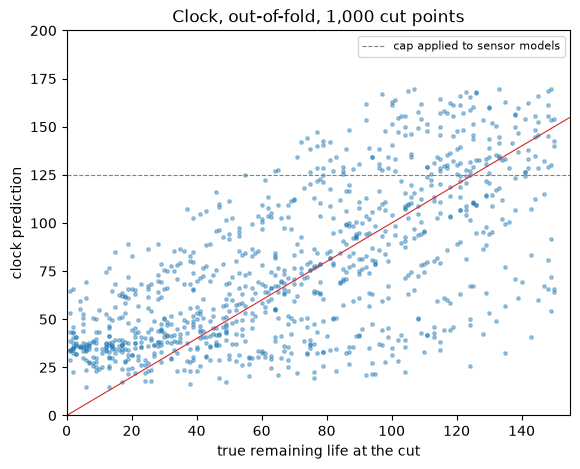

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(cuts["rul_true"], cuts["pred_clock"], s=6, alpha=0.4)
ax.plot([0, 200], [0, 200], color="C3", lw=0.8)
ax.axhline(RUL_CAP, color="grey", ls="--", lw=0.8, label="cap applied to sensor models")
ax.set(xlabel="true remaining life at the cut", ylabel="clock prediction", xlim=(0, 155), ylim=(0, 200),
       title="Clock, out-of-fold, 1,000 cut points")
ax.legend(fontsize=8)
plt.show()

**Reading.** The cap turned out to help the clock, not to handicap it. Capped at 125, the clock scores RMSE 31.5 and PHM08 5,441 per 100 predictions, against 33.4 and 6,921 uncapped. Its predictions above 125 are right on some of the cuts beyond the cap, but most of them belong to young engines that will actually fail sooner, where predicting more than 125 means predicting late. The capped clock is the stronger baseline, so it is the one every sensor model has to beat: **RMSE 31.5, PHM08 5,441 per 100 predictions.**

These are not the 35.9 and 6,820 from the test set in notebook 02. The cuts and the engines are different, and the test set stays out of development. What matters is that from now on every model is scored on these same 1,000 cut points.

The table by bin shows how the clock fails, and it is the same failure as in notebook 02, now on 100 engines instead of a handful:

- **Near failure it is late.** In the last 25 cycles it predicts 28 cycles too many on average. The scatter shows why: it never predicts much below 20 cycles, because among engines of a given age, half still have a typical remaining life ahead. An engine about to fail looks, by age alone, like any other engine of its age.
- **Far from failure it is early.** Above 100 cycles of remaining life it predicts too little, because young engines that will live long look like average ones.

Its error grows with remaining life, from 32 to 40 cycles of RMSE. A sensor model should improve most where the sensors carry signal, in the last 100 cycles or so, and above all fix the late predictions near failure, the most expensive errors under PHM08.

## 3. Linear baseline on the sensors

The simplest sensor model: OLS on the 12 sensors kept raw in notebook 01, using the reading at the cut cycle only. Sensors 9 and 14 need a per-engine baseline to be useful, which is a window feature and belongs to level 3.

The model is trained on every row of the four training folds, with the label capped at 125, and evaluated at the cut points of the fifth. Its predictions are clipped to the range 0 to 125, the same treatment as the clock: a remaining life cannot be negative, and nothing trained on the capped label should claim more than 125.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from turbofan_rul.config import FD001_RAW_SENSORS as SENSORS

cut_rows = cuts.merge(df[["unit", "cycle"] + SENSORS], on=["unit", "cycle"], how="left")
assert cut_rows[SENSORS].notna().all().all() and len(cut_rows) == len(cuts)


def oof_predict(make_model, features, data=df, target="rul"):
    # Train on four folds, predict the cut points of the fifth. Returns one prediction per cut.
    pred = np.empty(len(cut_rows))
    for f in range(N_FOLDS):
        train = data[data["fold"] != f]
        model = make_model().fit(train[features], train[target])
        in_fold = (cut_rows["fold"] == f).to_numpy()
        pred[in_fold] = model.predict(cut_rows.loc[in_fold, features])
    return pred


raw_linear = oof_predict(lambda: make_pipeline(StandardScaler(), LinearRegression()), SENSORS)
cuts["pred_linear"] = raw_linear.clip(0, RUL_CAP)
print(f"Predictions clipped: {(raw_linear > RUL_CAP).mean():.0%} above 125, {(raw_linear < 0).mean():.0%} below 0")

results.loc["linear, 12 sensors"] = summarize(cuts["rul_true"], cuts["pred_linear"])
results.round(1)

Predictions clipped: 4% above 125, 1% below 0


,rmse,phm08_per_100,mean_error
clock,33.4,6920.5,5.8
"clock, capped at 125",31.5,5440.9,2.7
"linear, 12 sensors",24.2,1536.1,4.9


In [9]:
# Coefficients of the model fitted on all training engines, in cycles of RUL per standard deviation
full = make_pipeline(StandardScaler(), LinearRegression()).fit(df[SENSORS], df["rul"])
coefs = pd.Series(full[-1].coef_, index=SENSORS).rename("cycles of RUL per std")
trend = pd.Series({s: ("rises" if s in ["sensor_2", "sensor_3", "sensor_4", "sensor_8", "sensor_11",
                                        "sensor_13", "sensor_15", "sensor_17"] else "falls") for s in SENSORS},
                  name="with degradation (notebook 01)")
pd.concat([coefs.round(1), trend], axis=1).sort_values("cycles of RUL per std")

,cycles of RUL per std,with degradation (notebook 01)
sensor_11,-8.1,rises
sensor_4,-6.6,rises
sensor_15,-5.1,rises
sensor_17,-4.3,rises
sensor_3,-3.7,rises
sensor_2,-3.6,rises
sensor_20,4.0,falls
sensor_21,4.2,falls
sensor_7,4.4,falls
sensor_13,4.8,rises


**Reading.** The linear model beats the clock clearly: RMSE 24.2 against 31.5, and a PHM08 score 3.5 times lower (1,536 against 5,441 per 100 predictions). One sensor reading at the cut already carries more information than the whole age distribution.

Ten of the twelve coefficients have the sign the physics predicts: sensors that rise with degradation push the prediction down, sensors that fall push it up. Sensors 8 and 13 are the exceptions: they rise with degradation but get positive coefficients. They are strongly correlated with the other rising sensors, and in a multiple regression each coefficient is the effect with the others held fixed (DIMAP 2.1). Their weight partly corrects what the rest already say, so reading them one by one as "the effect of sensor 8" would be wrong.

### 3a. Where the linear model errs

The same breakdown as for the clock, side by side. The question from section 2: does the linear model fix the late predictions near failure?

In [10]:
def by_bin_table(pred_cols):
    out = {}
    for col in pred_cols:
        err = cuts[col] - cuts["rul_true"]
        out[(col, "mean error")] = err.groupby(bins, observed=True).mean()
        out[(col, "RMSE")] = np.sqrt((err ** 2).groupby(bins, observed=True).mean())
    return pd.DataFrame(out)


by_bin_table(["pred_clock_capped", "pred_linear"]).round(1)

pred_clock_capped       pred_linear      
                  mean error  RMSE  mean error  RMSE
rul_true                                            
(0, 25]                 28.1  31.9        11.5  16.6
(25, 50]                15.3  26.7        23.4  28.1
(50, 75]                 4.0  28.0        17.6  23.9
(75, 100]               -4.2  32.7         5.5  19.6
(100, 125]             -12.9  32.4       -12.6  22.1
(125, 150]             -29.1  39.3       -31.8  36.1

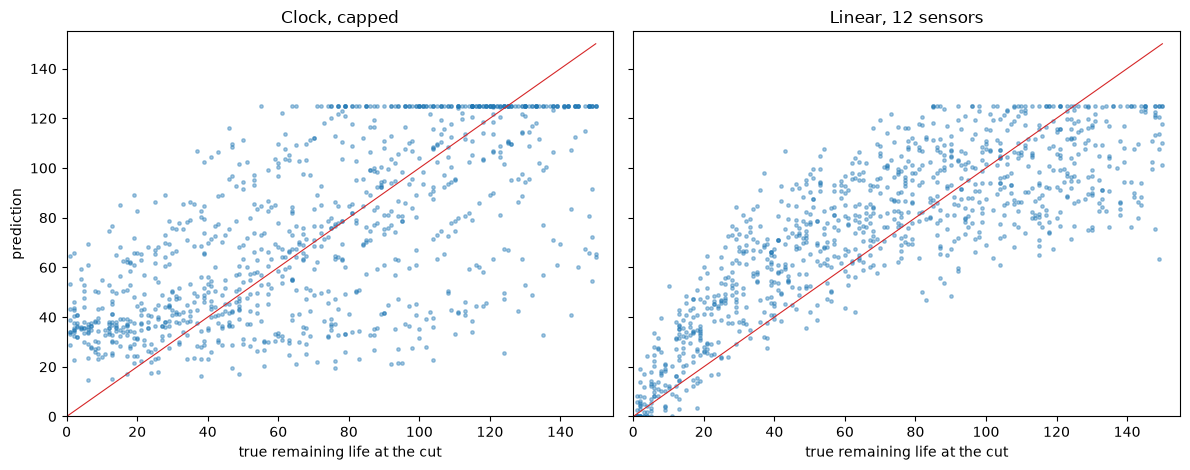

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, col, title in [(axes[0], "pred_clock_capped", "Clock, capped"), (axes[1], "pred_linear", "Linear, 12 sensors")]:
    ax.scatter(cuts["rul_true"], cuts[col], s=6, alpha=0.4)
    ax.plot([0, 150], [0, 150], color="C3", lw=0.8)
    ax.set(xlabel="true remaining life at the cut", title=title, xlim=(0, 155), ylim=(0, 155))
axes[0].set_ylabel("prediction")
plt.tight_layout()
plt.show()

**Reading.** The linear model improves where the clock was worst, but not uniformly:

- **In the last 25 cycles** it is late by 11.5 cycles on average, against 28 for the clock. The sensors do tell an engine about to fail from one of the same age.
- **Between 25 and 75 cycles from failure** it is late by 18 to 23 cycles, more than the clock. This is the bias predicted in DIMAP 2.2: degradation accelerates toward the end (notebook 01), and a straight line through the sensors cannot follow a curve. The scatter shows it as a band bent above the diagonal.
- **Its spread is much smaller everywhere.** The RMSE per bin drops from 26 to 33 for the clock to 17 to 28, and the scatter is a band instead of a cloud.

So the linear model wins on variance and loses part of it back on bias, in the expensive direction. That tells level 3 and 4 what to fix: a model that can follow the curvature of the degradation, not just more sensors. Above the cap both models fail by construction, as expected from section 1.

### 3b. Does regularization help?

DIMAP 2.5 predicts it will not: 12 sensors, 20,000 rows and moderate collinearity leave little variance to remove. The curves below score ridge and lasso over a range of penalties on the same cut points. This is a diagnostic, not a selection: if the curve is flat, there is nothing to choose, and picking its lowest point would only fit the noise of these 1,000 cuts (level 2, question 6).

In [12]:
from sklearn.linear_model import Lasso, Ridge

alphas = np.logspace(-2, 4, 13)
curve = pd.DataFrame(index=pd.Index(alphas, name="alpha"))
for name, make in [("ridge", lambda a: Ridge(alpha=a)), ("lasso", lambda a: Lasso(alpha=a / 1000, max_iter=10_000))]:
    curve[name] = [
        summarize(cuts["rul_true"], oof_predict(lambda make=make, a=a: make_pipeline(StandardScaler(), make(a)), SENSORS).clip(0, RUL_CAP))["rmse"]
        for a in alphas
    ]
curve["OLS"] = results.loc["linear, 12 sensors", "rmse"]
curve.round(2)

,ridge,lasso,OLS
alpha,,,
0.010000,24.18,24.18,24.18
0.031623,24.18,24.18,24.18
0.100000,24.18,24.18,24.18
0.316228,24.18,24.18,24.18
1.000000,24.18,24.18,24.18
3.162278,24.18,24.18,24.18
10.000000,24.18,24.18,24.18
31.622777,24.18,24.19,24.18
100.000000,24.18,24.20,24.18


**Reading.** The curves are flat. Ridge and lasso match OLS at 24.18 for every penalty up to about 100, and only get worse when the penalty is strong enough to shrink useful coefficients. There is no variance for regularization to remove: 12 features, 80 training engines and 16,000 rows. This confirms DIMAP 2.4 and 2.5 from the other side: the linear model's problem is bias. Regularization comes back at level 3, with around a hundred correlated window features.

### 3c. How much of the score is the draw of cut points?

The cut points were drawn once, with seed 0. To see how much the scores depend on that draw, both models are scored on 30 different draws. The models do not change, only which cycles are used as cuts.

In [13]:
row_preds = df[["unit", "cycle", "fold"]].copy()
row_preds["linear"] = np.nan
for f in range(N_FOLDS):
    train = df[df["fold"] != f]
    model = make_pipeline(StandardScaler(), LinearRegression()).fit(train[SENSORS], train["rul"])
    row_preds.loc[df["fold"] == f, "linear"] = model.predict(df.loc[df["fold"] == f, SENSORS])
    clock = WeibullClock().fit(lifetimes.loc[folds.index[folds != f]])
    row_preds.loc[df["fold"] == f, "clock"] = clock.predict(df.loc[df["fold"] == f, "cycle"])
row_preds[["linear", "clock"]] = row_preds[["linear", "clock"]].clip(0, RUL_CAP)

draws = []
for seed in range(30):
    c = sample_cut_points(df, seed=seed).merge(row_preds, on=["unit", "cycle"])
    draws.append({"seed": seed,
                  "linear": summarize(c["rul_true"], c["linear"])["rmse"],
                  "clock": summarize(c["rul_true"], c["clock"])["rmse"]})
draws = pd.DataFrame(draws).set_index("seed")
draws["clock - linear"] = draws["clock"] - draws["linear"]
draws.describe().loc[["mean", "std", "min", "max"]].round(2)

,linear,clock,clock - linear
mean,25.05,32.01,6.96
std,0.42,0.52,0.64
min,24.18,30.98,5.70
max,25.82,32.76,8.08


**Reading.** The same model scores differently depending on which cycles become cuts: the linear model's RMSE ranges from 24.2 to 25.8 over 30 draws, with a standard deviation of 0.4. Seed 0, the draw used in this notebook, is the most favourable of the 30 for the linear model, so the absolute numbers above are slightly optimistic.

The gap between the clock and the linear model moves too, from 5.7 to 8.1 cycles of RMSE, with a standard deviation of 0.6. It is not more stable than the scores themselves: the two models fail on different cuts, so a draw that is lucky for one is not necessarily lucky for the other. What is stable is the conclusion. In all 30 draws the linear model beats the clock by more than 5 cycles.

Two practical rules follow. A difference between models counts only if it clearly exceeds this noise: a gap of a few tenths of RMSE is not a result. And the final results table averages several draws instead of reporting one.

## 4. How much does a row-wise split inflate the score?

DIMAP 2.7 predicts that the size of the leak depends on the model and on the features. This section measures it under the protocol, with two feature sets and three models:

- **Raw:** the 12 sensor readings at the cut, as in section 3.
- **Smoothed:** a 30-cycle trailing mean of each sensor, computed within each engine, plus the engine's age. Neighbouring rows of an engine become near copies of each other.
- **Models:** linear regression, 5-nearest neighbours, and a random forest.

Engine-wise folds are the ones from section 1. Row-wise folds assign each row to one of five folds at random, ignoring the engine, so the other rows of a validation engine stay in training. Both are scored on the same 1,000 cut points.

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

SMOOTH = [f"{s}_mean30" for s in SENSORS]
df[SMOOTH] = df.groupby("unit")[SENSORS].transform(lambda c: c.rolling(30, min_periods=1).mean()).to_numpy()
df["row_fold"] = np.random.default_rng(0).integers(0, N_FOLDS, len(df))

feature_sets = {"raw": SENSORS, "smoothed + age": SMOOTH + ["cycle"]}
models = {
    "linear": lambda: make_pipeline(StandardScaler(), LinearRegression()),
    "5-nearest neighbours": lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(5)),
    "random forest": lambda: RandomForestRegressor(100, min_samples_leaf=5, n_jobs=-1, random_state=0),
}
cut_data = cuts[["unit", "cycle", "rul_true"]].merge(df, on=["unit", "cycle"], how="left")


def oof_at_cuts(make_model, features, fold_col):
    pred = np.empty(len(cut_data))
    for f in range(N_FOLDS):
        train = df[df[fold_col] != f]
        model = make_model().fit(train[features], train["rul"])
        in_fold = (cut_data[fold_col] == f).to_numpy()
        pred[in_fold] = model.predict(cut_data.loc[in_fold, features])
    return pred.clip(0, RUL_CAP)


leak = []
for fname, feats in feature_sets.items():
    for mname, make in models.items():
        by_engine = summarize(cut_data["rul_true"], oof_at_cuts(make, feats, "fold"))["rmse"]
        by_row = summarize(cut_data["rul_true"], oof_at_cuts(make, feats, "row_fold"))["rmse"]
        leak.append({"features": fname, "model": mname, "split by engine": by_engine,
                     "split by row": by_row, "apparent gain": by_engine - by_row})
leak = pd.DataFrame(leak).set_index(["features", "model"])
leak.round(1)

split by engine  split by row  \
features       model                                                 
raw            linear                           24.2          24.1   
               5-nearest neighbours             25.3          25.5   
               random forest                    24.0          24.0   
smoothed + age linear                           25.3          24.9   
               5-nearest neighbours             25.9           6.4   
               random forest                    23.9          11.5   

                                     apparent gain  
features       model                                
raw            linear                          0.1  
               5-nearest neighbours           -0.2  
               random forest                   0.0  
smoothed + age linear                          0.4  
               5-nearest neighbours           19.5  
               random forest                  12.4

**Reading.** With raw readings, the split makes no difference for any model: at most 0.2 cycles of RMSE, inside the noise measured in 3c. Sensor noise hides which engine a row comes from, so there is nothing to copy.

With smoothed features and age, neighbouring rows of an engine become near copies, and the flexible models copy them. Split by row, the 5-nearest-neighbours model drops from 25.9 to 6.4, and the random forest from 23.9 to 11.5. The linear model barely moves, 0.4 cycles, because a dozen global coefficients cannot store anything specific to one engine (level 2, question 7).

The row-wise split does not only inflate the scores, it reverses the ranking. Split by row, the nearest-neighbours model on smoothed features looks like the best model in this notebook by far. Split by engine, it is the worst. A project that validated by row would pick it and deploy the model that generalises worst to new engines. This is why the protocol from section 1 is not optional, and why the trap matters from level 3 on: window features and tree models are exactly the combination that exploits it.

## 5. Does the linear model beat the clock?

The verdict for this notebook, on the evidence of sections 2 to 4: scores averaged over the 30 draws of cut points from 3c, and a look at which engines each model gets most wrong.

In [15]:
from turbofan_rul.evaluation import phm08_per_100

final = []
for seed in range(30):
    c = sample_cut_points(df, seed=seed).merge(row_preds, on=["unit", "cycle"])
    for model in ["clock", "linear"]:
        final.append({"model": model, "seed": seed,
                      "rmse": summarize(c["rul_true"], c[model])["rmse"],
                      "phm08_per_100": phm08_per_100(c["rul_true"], c[model])})
final = pd.DataFrame(final).groupby("model")[["rmse", "phm08_per_100"]].agg(["mean", "std"])
final.index = ["clock, capped at 125", "linear, 12 sensors"]
final.round(1)

rmse      phm08_per_100       
                      mean  std          mean    std
clock, capped at 125  32.0  0.5        7358.6  988.5
linear, 12 sensors    25.0  0.4        1708.9  116.2

**Reading.** Averaged over 30 draws, the linear model scores RMSE 25.0 against 32.0 for the clock, and PHM08 1,709 per 100 predictions against 7,359. The PHM08 gap is more than four times larger than its spread across draws, and section 3c showed the linear model wins on every draw. The seed-0 numbers used in the earlier sections (24.2 and 31.5) are on the favourable side of these averages; the averages are the ones carried forward.

In [16]:
# Per-engine PHM08 on the seed-0 cuts: which engines carry each model's score?
def penalty(d):
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)

per_engine = pd.DataFrame({
    "lifetime": lifetimes,
    "clock": pd.Series(penalty(cuts["pred_clock_capped"] - cuts["rul_true"])).groupby(cuts["unit"]).sum(),
    "linear": pd.Series(penalty(cuts["pred_linear"] - cuts["rul_true"])).groupby(cuts["unit"]).sum(),
})
for m in ["clock", "linear"]:
    top10 = per_engine[m].nlargest(10)
    print(f"{m:6s}: worst 10 engines carry {top10.sum() / per_engine[m].sum():.0%} of the score; "
          f"their lifetimes: {sorted(per_engine.loc[top10.index, 'lifetime'].tolist())}")

life_bins = pd.qcut(per_engine["lifetime"], 4, labels=["shortest 25%", "second", "third", "longest 25%"])
per_engine.groupby(life_bins, observed=True)[["clock", "linear"]].mean().round(0)

clock : worst 10 engines carry 59% of the score; their lifetimes: [128, 135, 137, 137, 283, 287, 293, 313, 341, 362]
linear: worst 10 engines carry 37% of the score; their lifetimes: [153, 154, 165, 166, 195, 200, 201, 202, 267, 275]


,clock,linear
lifetime,,
shortest 25%,1059.0,201.0
second,49.0,121.0
third,32.0,170.0
longest 25%,1035.0,128.0


**Reading.** The two models fail on different engines.

- **The clock fails at the extremes of the fleet.** Its 10 worst engines carry 59% of its score, and they are the shortest-lived (128 to 137 cycles) and the longest-lived (283 to 362). By age alone, both look like typical engines: the short-lived ones are predicted to last too long, the long-lived ones to fail too soon.
- **The linear model spreads its errors.** Its 10 worst engines carry 37% of its score and have ordinary lifetimes, from 153 to 275. The sensors see the degradation of unusual engines, so the extremes stop being a problem.
- **On typical engines the clock is better.** In the two middle quartiles of lifetime, the clock's mean penalty per engine is 32 to 49, against 121 to 170 for the linear model. For an engine that behaves like the average, age is a very good predictor, and the linear model's bias in the 25 to 75 band costs more than the clock's error.

That last point matters for level 3. Age and sensors carry complementary information: age is precise for typical engines, sensors catch the unusual ones. A model that uses both should beat either on its own.

## 6. Logging the baselines

The two baselines become the first runs of the project's MLflow experiment, `fd001-development`. Each run stores the protocol settings, the model settings, the scores averaged over 30 draws and on the seed-0 cuts, the git commit, and the out-of-fold predictions as a CSV. Every later model is logged the same way, so the comparison between models lives in one place instead of being copied between notebooks.

The helpers are in `src/turbofan_rul/tracking.py`. Runs are stored locally at the project root and are not committed. Re-running this notebook logs new runs rather than overwriting the old ones.

In [17]:
from turbofan_rul.tracking import log_model_run, start_experiment

start_experiment("fd001-development")

baselines = {
    "clock-weibull3-capped": ("pred_clock_capped", "clock, capped at 125",
                              {"model": "WeibullClock", "features": "age", "prediction_clip": "0-125"}),
    "linear-12-sensors": ("pred_linear", "linear, 12 sensors",
                          {"model": "OLS", "features": "raw:" + ",".join(SENSORS), "prediction_clip": "0-125"}),
}
for run_name, (col, row, params) in baselines.items():
    metrics = {
        "rmse_mean": final.loc[row, ("rmse", "mean")],
        "rmse_std": final.loc[row, ("rmse", "std")],
        "phm08_per_100_mean": final.loc[row, ("phm08_per_100", "mean")],
        "phm08_per_100_std": final.loc[row, ("phm08_per_100", "std")],
        "n_draws": 30,
    }
    metrics.update({f"seed0_{k}": v for k, v in summarize(cuts["rul_true"], cuts[col]).items()})
    preds = cuts[["unit", "cycle", "fold", "rul_true"]].assign(pred=cuts[col])
    log_model_run(run_name, params, metrics, predictions=preds, tags={"notebook": "03_linear_baseline"})

import mlflow

logged = mlflow.search_runs(experiment_names=["fd001-development"], order_by=["start_time DESC"])
logged[["tags.mlflow.runName", "metrics.rmse_mean", "metrics.phm08_per_100_mean", "tags.git_commit"]].head(2).round(1)

,tags.mlflow.runName,metrics.rmse_mean,metrics.phm08_per_100_mean,tags.git_commit
0,linear-12-sensors,25.0,1708.9,bd2e5b7
1,clock-weibull3-capped,32.0,7358.6,bd2e5b7


### 5a. Uncertainty over engines: per-fold scores

The 30 draws in 3c resample cut points on the same 100 engines. The larger source of uncertainty is which engines are in the fleet. The per-fold scores show it: each fold is a different set of 20 validation engines.

In [18]:
per_fold = pd.DataFrame({
    m: cuts.groupby("fold").apply(lambda g, col=col: summarize(g["rul_true"], g[col])["rmse"], include_groups=False)
    for m, col in [("clock", "pred_clock_capped"), ("linear", "pred_linear")]
})
per_fold["clock - linear"] = per_fold["clock"] - per_fold["linear"]
per_fold.loc["mean"] = per_fold.mean()
per_fold.loc["std"] = per_fold.iloc[:-1].std()
per_fold.round(1)

,clock,linear,clock - linear
fold,,,
0,31.5,24.5,7.0
1,31.0,22.1,8.9
2,32.6,24.1,8.5
3,30.6,26.4,4.1
4,31.9,23.6,8.3
mean,31.5,24.1,7.4
std,0.8,1.6,2.0


**Reading.** Across folds the linear model's RMSE ranges from 22.1 to 26.4 and the gap to the clock from 4.1 to 8.9, with a standard deviation of 2.0. That is three times the draw-to-draw noise from 3c: which engines are in the fleet matters more than which cycles are cut. The conclusion holds in every fold, but a gap of 2 cycles between two models would not be a result under this protocol. Per-fold scores are reported for every model from here on.

### 5b. Are the results sensitive to the protocol constants?

Minimum history, planning limit and cuts per engine were chosen once, with reasons, but without checking that the conclusions survive other reasonable values. One check, then the constants are left alone.

In [19]:
sensitivity = []
for min_hist, limit, n_cuts in [(30, 150, 10), (20, 150, 10), (50, 150, 10), (30, 125, 10), (30, 200, 10), (30, 150, 5), (30, 150, 20)]:
    c = sample_cut_points(df, n_cuts=n_cuts, min_history=min_hist, planning_limit=limit).merge(row_preds, on=["unit", "cycle"])
    row = {"min_history": min_hist, "planning_limit": limit, "cuts_per_engine": n_cuts, "n_cuts": len(c)}
    for m in ["clock", "linear"]:
        sc = summarize(c["rul_true"], c[m])
        row[f"{m} RMSE"] = sc["rmse"]
        row[f"{m} PHM08/100"] = sc["phm08_per_100"]
    sensitivity.append(row)
sensitivity = pd.DataFrame(sensitivity).set_index(["min_history", "planning_limit", "cuts_per_engine"])
sensitivity.round(0).astype(int)

n_cuts  clock RMSE  \
min_history planning_limit cuts_per_engine                       
30          150            10                 1000          32   
20          150            10                 1000          31   
50          150            10                 1000          33   
30          125            10                 1000          29   
            200            10                 1000          36   
            150            5                   500          31   
                           20                 2000          32   

                                            clock PHM08/100  linear RMSE  \
min_history planning_limit cuts_per_engine                                 
30          150            10                          5441           24   
20          150            10                          5143           24   
50          150            10                          6071           24   
30          125            10                          3955           22   
            200            10                         13692           31   
            150            5                           5365           25   
                           20                          7676           24   

                                            linear PHM08/100  
min_history planning_limit cuts_per_engine                    
30          150            10                           1536  
20          150            10                           1654  
50          150            10                           1699  
30          125            10                           1278  
            200            10                           5265  
            150            5                            1787  
                           20                           1574

**Reading.** Minimum history and cuts per engine barely move the scores: RMSE 31 to 33 for the clock and 24 to 25 for the linear model. The planning limit is the one constant that matters, and only for the absolute numbers: with a limit of 200, cuts with a true RUL above the cap become common, every capped model pays the floor, and the linear model's PHM08 triples. The ranking does not change in any setting. The constants stay as they are, and the planning limit is recorded as the assumption that most affects absolute scores.

---

## Decisions

| # | Question | Decision | Evidence |
|---|----------|----------|----------|
| 1 | Folds | 5 folds by engine, stratified by lifetime: engines sorted by lifetime, dealt in blocks of five with shuffled labels. Code in `src/turbofan_rul/validation.py` | Section 1a: every fold has a median life of 197 to 199 and at least one engine above 290 |
| 2 | Cut points and metrics | Cuts after at least 30 observed cycles, true RUL between 1 and 150, 10 per engine. Scored against the true, uncapped RUL. Predictions clipped to 0 to 125. RMSE and PHM08 per 100 predictions | Section 1b. The 11% of cuts above 125 cost every capped model the same floor |
| 3 | Noise rule | Scores are the mean over 30 draws of cut points, reported with per-fold values. A difference between models counts only if it clearly exceeds the fold-to-fold spread (gap std about 2 cycles of RMSE), which is three times the draw-to-draw noise | Sections 3c and 5a |
| 4 | Development baseline | Clock capped at 125: RMSE 32.0, PHM08 7,359 per 100 (mean over 30 draws). Capping helps the clock, so the capped version is the one to beat | Sections 2 and 5 |
| 5 | Linear baseline | OLS on the 12 raw sensors: RMSE 25.0, PHM08 1,709 per 100. Beats the clock on every draw. Late by 18 to 23 cycles between 25 and 75 cycles from failure. Ridge and lasso change nothing | Sections 3 and 5 |
| 6 | Leakage | Engine-wise splits only, and features computed from the past only (trailing windows). A row-wise split inflated the score of flexible models on smoothed features by 12 to 20 cycles and reversed the model ranking | Section 4 |
| 7 | Scoring convention | Development scores compare predictions with the true, uncapped RUL, because that is what the planner faces. Every model trained on the capped label pays the same floor on the 11% of cuts above 125, so rankings are unaffected but absolute RMSE is higher than in the literature, which scores against capped labels. The final test-set table will report both conventions | Sections 1b and 5b |
| 8 | Protocol constants | Kept as chosen (30 cycles of history, planning limit 150, 10 cuts per engine). Minimum history and cuts per engine do not change scores or ranking; the planning limit changes absolute scores only | Section 5b |

Notes to carry into notebook 04 (window features and gradient boosting):

- The linear model's main problem is bias: a straight line cannot follow accelerating degradation. Models that can bend (level 4) or features that describe the rate of change are the fix, not more regularization.
- Long trailing windows lag behind the engine's state. In a quick check outside this notebook, a 5-cycle mean slightly improved on raw values and a 30-cycle mean made the linear model worse, while giving it both the raw value and the 30-cycle mean improved it to about 22.5. The difference between current value and recent average is a trend: build slopes and differences deliberately, and verify these numbers under the protocol.
- Age is not redundant with the sensors: the clock beats the linear model on typical engines. Test age, and the clock's prediction itself, as features.
- Sensors 9 and 14 are still unused: they need the per-engine baseline from notebook 01.
- Regularization becomes relevant with around a hundred correlated window features. Tune it inside the training folds, never on the evaluation cuts.
- Every new model reuses `engine_folds`, `sample_cut_points` and `summarize`, is reported as the mean over 30 draws, and is logged to the `fd001-development` MLflow experiment with `log_model_run`.